# Fetal Health Analysis

Fetal and maternal health during birth are one of the main concerns of United Nations. Global maternal and fetal health outcomes have drastically improved in the last decades, however stark regional and socioeconomic disparities persist. According to WHO and UNICEF, most maternal deaths during childbirth are preventable with timely access to skilled obstetric care. Additionally data from UN IGME highlights that the period during birth and the first month after carries the highest risk for the fetus and newborn. This project strives to find which health markers have the biggest significance for the outcome of labour.


## Main hypothesis

**$H_1$:** Abnormal short-term variability, prolonged and severe decelerations differ between Normal, Suspect и Pathological.

**$H_{01}$** FHR abnormalities are not associated with abnormal neonatal outcomes.

**$H_2$:** The presence of pathological FHR patterns is associated with a greater likelihood of umbilical cord blood pH below 7.15.

**$H_{02}$** There is no difference between FHR patterns in newborns with pH>7.15 and those with pH>7.15

**$H_3$:** A combination of reduced variability, prolonged decelerations and late decelerations provides better discrimination between normal and abnormal neonatal outcomes than individual FHR markers.

**$H_{03}$** There is no change in finding acidemia.


In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from pathlib import Path

The first dataset is CTU-UHB Intrapartum Cardiotocography Database - a collection of 552 CTGs from the Czech Technical University (CTU) in Prague and the University Hospital in Brno (UHB). *Each recording is up to 90 minutes long, and includes a fetal heart rate time series, a uterine contraction signal, and maternal, delivery, and fetal clinical details.*

In [3]:
data_dir = Path("data/ctu-uhb-ctgdb-1.0.0")
names = sorted(p.stem for p in data_dir.glob("*.hea"))
rows = []
for name in names:
    h = wfdb.rdheader(str(data_dir / name))
    info = {"record": name}
    for line in h.comments:
        line = line.lstrip("#").strip()
        if not line or line.startswith(("-", "!")):
            continue
        key, value = line.rsplit(None, 1)
        try:
            info[key] = float(value)
        except ValueError:
            info[key] = value
    rows.append(info)
df_clinical = pd.DataFrame(rows)

In [4]:
df_clinical

,record,pH,BDecf,pCO2,BE,Apgar1,Apgar5,NICU days,Seizures,HIE,...,Induced,I.stage,NoProgress,CK/KP,II.stage,Deliv. type,dbID,Rec. type,Pos. II.st.,Sig2Birth
0,1001,7.14,8.14,7.7,-10.5,6.0,8.0,0.0,0.0,0.0,...,0.0,232.0,0.0,0.0,20.0,1.0,974204.0,1.0,14400.0,0.0
1,1002,7.00,7.92,12.0,-12.0,8.0,8.0,0.0,0.0,0.0,...,0.0,220.0,0.0,0.0,20.0,1.0,975666.0,1.0,14400.0,0.0
2,1003,7.20,3.03,8.3,-5.6,7.0,9.0,0.0,0.0,0.0,...,1.0,215.0,0.0,0.0,15.0,1.0,982315.0,1.0,14400.0,0.0
3,1004,7.30,5.19,5.5,-6.4,8.0,9.0,0.0,0.0,0.0,...,1.0,55.0,0.0,0.0,10.0,1.0,983277.0,12.0,14400.0,0.0
4,1005,7.30,4.52,5.7,-5.8,9.0,10.0,0.0,0.0,0.0,...,1.0,114.0,0.0,0.0,15.0,1.0,983398.0,1.0,14400.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547,2042,7.33,-0.50,6.6,-0.8,9.0,10.0,0.0,0.0,0.0,...,0.0,255.0,0.0,1.0,15.0,2.0,1072108.0,1.0,15482.0,0.0
548,2043,7.08,10.92,7.9,-13.3,8.0,9.0,0.0,0.0,0.0,...,0.0,260.0,0.0,1.0,25.0,2.0,1078408.0,1.0,14400.0,0.0
549,2044,7.02,9.13,10.6,-12.3,8.0,8.0,0.0,0.0,0.0,...,1.0,335.0,1.0,0.0,-1.0,2.0,1079432.0,1.0,-1.0,0.0
550,2045,7.03,8.91,10.4,-12.2,7.0,9.0,0.0,0.0,0.0,...,0.0,189.0,0.0,0.0,-1.0,2.0,1083243.0,1.0,-1.0,0.0


In [5]:
print(df_clinical["Sex"].value_counts(dropna=False))
print(df_clinical["Presentation"].value_counts(dropna=False))

Sex
1.0    286
2.0    266
Name: count, dtype: int64
Presentation
1.0    499
3.0     32
2.0     18
NaN      3
Name: count, dtype: int64


In [6]:
df_clinical.to_csv("clinical_ctu_chb.csv")

In [7]:
df_clinical.columns

Index(['record', 'pH', 'BDecf', 'pCO2', 'BE', 'Apgar1', 'Apgar5', 'NICU days',
       'Seizures', 'HIE', 'Intubation', 'Main diag.', 'Other diag.',
       'Gest. weeks', 'Weight(g)', 'Sex', 'Age', 'Gravidity', 'Parity',
       'Diabetes', 'Hypertension', 'Preeclampsia', 'Liq. praecox', 'Pyrexia',
       'Meconium', 'Presentation', 'Induced', 'I.stage', 'NoProgress', 'CK/KP',
       'II.stage', 'Deliv. type', 'dbID', 'Rec. type', 'Pos. II.st.',
       'Sig2Birth'],
      dtype='str')

In [8]:
df_clinical.dtypes

record              str
pH              float64
BDecf           float64
pCO2            float64
BE              float64
Apgar1          float64
Apgar5          float64
NICU days       float64
Seizures        float64
HIE             float64
Intubation      float64
Main diag.      float64
Other diag.     float64
Gest. weeks     float64
Weight(g)       float64
Sex             float64
Age             float64
Gravidity       float64
Parity          float64
Diabetes        float64
Hypertension    float64
Preeclampsia    float64
Liq. praecox    float64
Pyrexia         float64
Meconium        float64
Presentation    float64
Induced         float64
I.stage         float64
NoProgress      float64
CK/KP           float64
II.stage        float64
Deliv. type     float64
dbID            float64
Rec. type       float64
Pos. II.st.     float64
Sig2Birth       float64
dtype: object

Since the values in the dataframe have been extracting form a raw text file, containing no information about their format, the first step would be to transform them in the correct type.

In [9]:
cat_cols = ["Presentation", "Deliv. type", "Sex", "Diabetes",
            "Hypertension", "Preeclampsia", "Induced", "Meconium", "Rec. type", "Liq. praecox", "Pyrexia"]
for c in cat_cols:
    df_clinical[c] = df_clinical[c].astype("category")

Numerical data can be turned into meaningful content in respect to its corresponding code.

In [10]:
df_clinical["Sex"] = df_clinical["Sex"].map({1 :"female" , 2: "male"})
df_clinical["Presentation"] = df_clinical["Presentation"].map({1: "normal",2: "breech",3: "other"})
df_clinical["Deliv. type"] = df_clinical["Deliv. type"].map({1: "vaginal",2: "cs"})
df_clinical["Rec. type"] = df_clinical["Rec. type"].map({1: "USG",2: "FECG",12: "combined"})

In [11]:
df_clinical.rename(columns={"BE": "Base excess"}, inplace=True)

/var/folders/fl/dqlmf5t178bghccm7nwd121h0000gn/T/ipykernel_9639/2883172611.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clinical.rename(columns={"BE": "Base excess"}, inplace=True)


Getting to know the dataset, finding missing value, etc.

<BarContainer object of 3 artists>

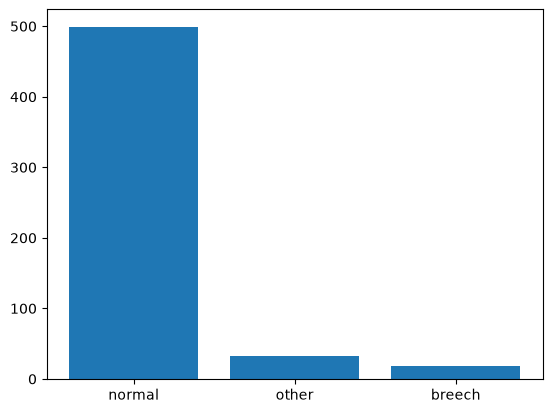

In [12]:
plt.bar(df_clinical["Presentation"].value_counts().index, df_clinical["Presentation"].value_counts().values)

<BarContainer object of 7 artists>

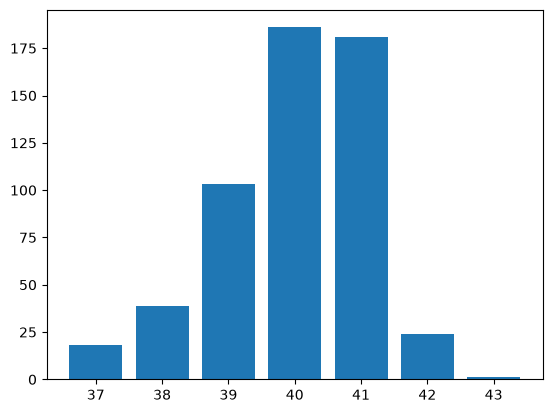

In [13]:
plt.bar(df_clinical["Gest. weeks"].value_counts().index, df_clinical["Gest. weeks"].value_counts().values)

In [14]:
print(df_clinical["Liq. praecox"].value_counts())
print(df_clinical[df_clinical["Liq. praecox"]==1.0]["Gest. weeks"].value_counts())

Liq. praecox
0.0    405
1.0    147
Name: count, dtype: int64
Gest. weeks
40.0    59
39.0    35
41.0    33
38.0     9
37.0     8
42.0     3
Name: count, dtype: int64


The difference in the counts of these subgroups points to the biological definition of liquor praecox - premature ruptance of membranes, that can cause infection and other complications. After the 37th week it is known as term premature ruptance of membranes, because the fetus is considered term, but mother's water is breaking before active labour has begun. This could be an interesting point of the analysis later on.

In [15]:
print(df_clinical["Diabetes"].value_counts())
print(df_clinical["Hypertension"].value_counts())
print(df_clinical["Preeclampsia"].value_counts())

Diabetes
0.0    515
1.0     37
Name: count, dtype: int64
Hypertension
0.0    508
1.0     44
Name: count, dtype: int64
Preeclampsia
0.0    535
1.0     17
Name: count, dtype: int64


Preeclampsia is a pregnancy complication that causes high blood pressure and signals organ stress. In such cases a safety measure is induced birth. The counts may overlap with those for hypertension.

In [16]:
print(df_clinical[df_clinical["Preeclampsia"]==1.00]["Hypertension"].value_counts())
print(df_clinical[df_clinical["Preeclampsia"]==1.00]["Induced"].value_counts())

Hypertension
0.0    12
1.0     5
Name: count, dtype: int64
Induced
1.0    11
0.0     6
Name: count, dtype: int64


In [17]:
miss = df_clinical.isnull().sum().to_frame("n_missing")
miss["pct"] = (miss["n_missing"] / df_clinical.shape[0]) * 100
miss.sort_values("pct", ascending=False)

,n_missing,pct
BDecf,11,1.992754
pCO2,11,1.992754
Base excess,11,1.992754
Gravidity,4,0.724638
Presentation,3,0.543478
Rec. type,2,0.362319
Weight(g),1,0.181159
record,0,0.000000
I.stage,0,0.000000
Pyrexia,0,0.000000


There could be cases in which the missing values can be hidden through placeholders, such as values that are impossible for the particular marker

In [18]:
df_clinical.iloc[:, [x for x in range (7)]].describe()

,pH,BDecf,pCO2,Base excess,Apgar1,Apgar5
count,552.000000,541.000000,541.000000,541.000000,552.000000,552.000000
mean,7.230054,4.601904,7.069501,-6.384104,8.262681,9.068841
std,0.105039,3.553392,1.556686,3.827455,1.624959,1.085613
min,6.850000,-3.400000,0.700000,-26.800000,1.000000,4.000000
25%,7.170000,2.490000,5.900000,-8.000000,8.000000,9.000000
50%,7.250000,4.130000,7.000000,-5.600000,9.000000,9.000000
75%,7.300000,6.140000,7.900000,-4.000000,9.000000,10.000000
max,7.470000,26.110000,12.300000,-0.200000,10.000000,10.000000


By looking at the minimum and maximum values of these specific markers, we can come to the conclusion that there are no hidden missing values.

Now let's ask the question what missingness actually means for this dataset.

In [19]:
df_clinical["BDecf_missing"] = df_clinical["BDecf"].isna()
df_clinical.groupby("BDecf_missing")[["pH", "pCO2", "Gest. weeks", "Weight(g)"]].agg(["mean", "std", "median"]).T

BDecf_missing             False        True 
pH          mean       7.232292     7.120000
            std        0.100581     0.219180
            median     7.250000     7.020000
pCO2        mean       7.069501          NaN
            std        1.556686          NaN
            median     7.000000          NaN
Gest. weeks mean      39.992606    40.090909
            std        1.127083     1.445998
            median    40.000000    40.000000
Weight(g)   mean    3399.324074  3454.545455
            std      455.897000   411.688320
            median  3410.000000  3610.000000

From this table we can deduct that **pCO2** and **BDecf** are missing together.

In [20]:
cols = ["BDecf", "pCO2", "Base excess"]
df_clinical[cols].isna().value_counts()

BDecf  pCO2   Base excess
False  False  False          541
True   True   True            11
Name: count, dtype: int64

In [21]:
df_clinical["th_missing"] = df_clinical[["BDecf", "pCO2", "Base excess"]].isna().all(axis=1)
df_clinical.groupby("th_missing")[["pH", "Apgar1", "Apgar5"]].agg(["count", "mean", "std", "median"]).T

th_missing          False      True 
pH     count   541.000000  11.000000
       mean      7.232292   7.120000
       std       0.100581   0.219180
       median    7.250000   7.020000
Apgar1 count   541.000000  11.000000
       mean      8.264325   8.181818
       std       1.627997   1.537412
       median    9.000000   8.000000
Apgar5 count   541.000000  11.000000
       mean      9.066543   9.181818
       std       1.088326   0.981650
       median    9.000000   9.000000

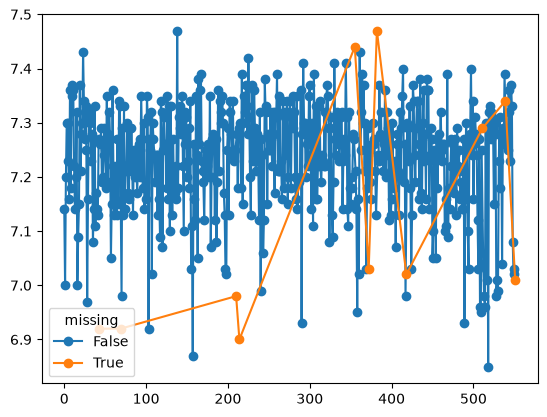

In [22]:
for name, group in df_clinical.groupby("th_missing"):
    plt.plot(group.index, group["pH"], label=name, marker="o")
plt.legend(title = "missing")
plt.show()

Here little, but noticeable differences in the mean and median are present. Such differences can be due to the small subset that represents the records with missing values. Another interpretation requires biology and chemistry knowledge.

**BDecf** stands for base deficit of extracellular fluid and measures metabolic acid accumulation in blood, assessed in umbilical cord blood gases at birth; evaluation of metabolic acidosis

**pCO2** measures the partial pressure of $CO_2$ in fetal blood. It is typically evaluated via umbilical cord blood gas analysis at delivery; evaluation of acid-base balance and placental gas exchange

**Base excess** measures metabolic acid-base balance via umbilical artery right after birth, it defines the amount of strong acid (in $mmol/L$) needed to return a standart pH of 7.4 at a pCO2 of 40 mmHg and 37ºC; evaluation of oxygen deprivation and metabolic acidosis

As we can see, these three measures are all related to acidity, measured after birth. The records with missing values for them have a lower median pH, so BDecf analyses underrepresent severely academic cases. In a small set of only 11 records with a standart deviation almost twice as big as that of the other subset the means are unstable, since a few cases can drive the difference.

The dataset contains 552 observations, of which 541 (98.01%) are complete, while only 11 (1.99%) contain missing values. This indicates a relatively low degree of missingness, suggesting that missing data are unlikely to substantially compromise the overall completeness of the dataset. Visual inspection of the missingness distribution did not reveal any apparent systematic patterns. Missing values appear to be randomly distributed across the observations.

Extracting FHR data from CTU-UHB dataset

In [23]:
def clean_name(name):
    return (name.strip().replace(" ", "_").replace(".", "").replace("(", "").replace(")", "").replace("/", "_"))
def read_header(hea_path):
    lines = Path(hea_path).read_text().splitlines()
    struct = [l for l in lines if l.strip() and not l.startswith("#")]
    comments = [l for l in lines if l.startswith("#")]
    first = struct[0].split()
    n_sig, fs, n_samp = int(first[1]), int(first[2]), int(first[3])
    signals = []
    for line in struct[1:1 + n_sig]:
        f = line.split()
        signals.append({
            "format": int(f[1]),
            "gain": float(f[2].split("(")[0].split("/")[0]),
            "zero": int(f[4]),
            "first_value": int(f[5]),
            "name": f[-1],
        })
    params = {}
    for line in comments:
        if len(line) < 2 or line[1] == "-":
            continue
        key = clean_name(line[1:14])
        try:
            params[key] = float(line[14:])
        except ValueError:
            params[key] = np.nan
    return {"n_sig": n_sig, "fs": fs, "n_samples": n_samp,
            "signals": signals, "params": params}

In [24]:
def read_signals(dat_path, hdr):
    if hdr["signals"][0]["format"]!=16:
        raise ValueError
    raw = np.fromfile(dat_path, dtype="<i2", count=hdr["n_samples"] * hdr["n_sig"])
    data = raw.reshape(-1, hdr["n_sig"])
    for i, s in enumerate(hdr["signals"]):
        if data [0, i] != s["first_value"]:
            raise ValueError
    fhr = (data[:, 0] - hdr["signals"][0]["zero"]) / hdr["signals"][0]["gain"]
    uc  = (data[:, 1] - hdr["signals"][1]["zero"]) / hdr["signals"][1]["gain"]
    return fhr, uc
def load_record(name, data_dir, trim_second_stage=False):
    data_dir = Path(data_dir)
    hdr = read_header(data_dir / f"{name}.hea")
    fhr, uc = read_signals(data_dir / f"{name}.dat", hdr)
    if trim_second_stage:
        pos = int(hdr["params"].get("Pos_IIst", -1))
        if pos != -1:
            fhr, uc = fhr[:pos], uc[:pos]
    return fhr, uc, hdr["params"], hdr["fs"]

7.14 14400.0


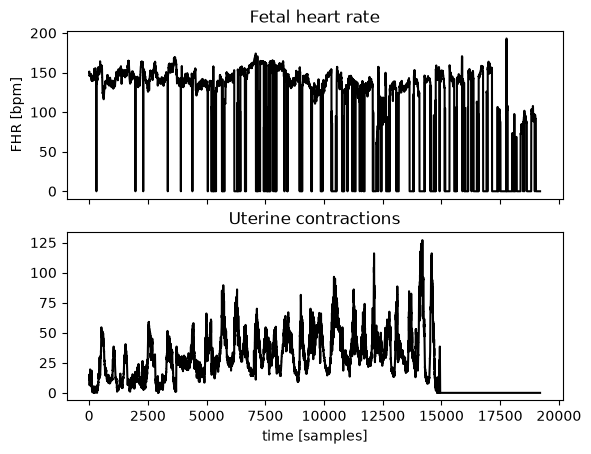

In [26]:
fhr, uc, params, fs = load_record("1001", data_dir)
fig, ax = plt.subplots(2, 1, sharex=True)
ax[0].plot(fhr, "k"); ax[0].set_title("Fetal heart rate"); ax[0].set_ylabel("FHR [bpm]")
ax[1].plot(uc, "k");  ax[1].set_title("Uterine contractions"); ax[1].set_xlabel("time [samples]")
print(params["pH"], params["Pos_IIst"])

Building the whole table of medical data and signal samples.

In [27]:
rows = []
for name in names:
    fhr, uc, params, fs = load_record(name, data_dir, trim_second_stage=True)
    fhr = np.where(fhr==0, np.nan, fhr)
    rows.append({"record": name, **params, "minutes_stage_1": len(fhr)/fs/60, "dropout": np.isnan(fhr).mean()})
df = pd.DataFrame(rows)
df

,record,pH,BDecf,pCO2,BE,Apgar1,Apgar5,NICU_days,Seizures,HIE,...,NoProgress,CK_KP,IIstage,Deliv_type,dbID,Rec_type,Pos_IIst,Sig2Birth,minutes_stage_1,dropout
0,1001,7.14,8.14,7.7,-10.5,6.0,8.0,0.0,0.0,0.0,...,0.0,0.0,20.0,1.0,974204.0,1.0,14400.0,0.0,60.000000,0.133889
1,1002,7.00,7.92,12.0,-12.0,8.0,8.0,0.0,0.0,0.0,...,0.0,0.0,20.0,1.0,975666.0,1.0,14400.0,0.0,60.000000,0.090486
2,1003,7.20,3.03,8.3,-5.6,7.0,9.0,0.0,0.0,0.0,...,0.0,0.0,15.0,1.0,982315.0,1.0,14400.0,0.0,60.000000,0.183472
3,1004,7.30,5.19,5.5,-6.4,8.0,9.0,0.0,0.0,0.0,...,0.0,0.0,10.0,1.0,983277.0,12.0,14400.0,0.0,60.000000,0.004514
4,1005,7.30,4.52,5.7,-5.8,9.0,10.0,0.0,0.0,0.0,...,0.0,0.0,15.0,1.0,983398.0,1.0,14400.0,0.0,60.000000,0.209514
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547,2042,7.33,-0.50,6.6,-0.8,9.0,10.0,0.0,0.0,0.0,...,0.0,1.0,15.0,2.0,1072108.0,1.0,15482.0,0.0,64.508333,0.104508
548,2043,7.08,10.92,7.9,-13.3,8.0,9.0,0.0,0.0,0.0,...,0.0,1.0,25.0,2.0,1078408.0,1.0,14400.0,0.0,60.000000,0.207708
549,2044,7.02,9.13,10.6,-12.3,8.0,8.0,0.0,0.0,0.0,...,1.0,0.0,-1.0,2.0,1079432.0,1.0,-1.0,0.0,79.625000,0.250968
550,2045,7.03,8.91,10.4,-12.2,7.0,9.0,0.0,0.0,0.0,...,0.0,0.0,-1.0,2.0,1083243.0,1.0,-1.0,0.0,62.058333,0.160870


In [28]:
n0 = len(df)
df = df[df["minutes_stage_1"]>=30]
n1 = len(df)
df = df[df["dropout"]<0.5]
n2 = len(df)
df["academia"] = df["pH"]<7.15
print(n0, n1, n2, df["academia"].sum())

552 552 550 104


Therefore, out of this dataset there are 2 cases in which the signals were not available for 50% of the duration.
The next step in the analysis would be comparasion of the maternal factors, such as age, gravidity, comorbidities, etc. in the academia and non-academia subgroups.

Age               float64
Gravidity         float64
Parity            float64
Diabetes         category
Hypertension     category
Preeclampsia     category
Liq. praecox     category
Pyrexia          category

In [29]:
df_clinical_ac = df_clinical[df_clinical["pH"]<7.15]
df_clinical_ac.groupby("Age")[["pH", "BDecf", "pCO2", "Base excess"]].agg(["count", "mean", "median", "std"])

pH                            BDecf                               \
     count      mean median       std count       mean  median       std   
Age                                                                        
19.0     1  7.010000  7.010       NaN     0        NaN     NaN       NaN   
21.0     1  6.960000  6.960       NaN     1  20.340000  20.340       NaN   
22.0     3  7.126667  7.140  0.023094     3   7.106667   7.350  1.174067   
23.0     3  7.006667  7.000  0.090185     2   8.265000   8.265  0.487904   
24.0     2  7.135000  7.135  0.007071     2   7.290000   7.290  1.527351   
25.0     6  7.081667  7.110  0.073052     6   9.620000   8.910  3.677178   
26.0     7  7.054286  7.070  0.062144     6  10.231667   9.695  3.421815   
27.0    15  7.046667  7.110  0.101887    15  10.994667   9.060  5.011980   
28.0     9  7.044444  7.050  0.076012     9  10.737778   8.610  5.676272   
29.0    11  7.090909  7.110  0.051856    11   7.802727   6.750  2.979967   
30.0     9  7.073333  7.100  0.075333     8   9.441250   8.755  5.750373   
31.0     5  7.050000  7.130  0.114237     4   7.375000   7.110  3.434264   
32.0     6  7.110000  7.120  0.040988     6   7.941667   8.200  1.260054   
33.0     6  7.050000  7.040  0.056921     6  10.911667   9.355  4.340569   
34.0     3  7.070000  7.130  0.103923     3   7.876667   7.560  3.416026   
35.0     6  7.056667  7.050  0.034448     6   7.078333   7.245  1.554020   
36.0     2  7.055000  7.055  0.106066     2  10.750000  10.750  5.147737   
37.0     4  7.047500  7.035  0.069940     3   9.496667   8.480  2.272495   
38.0     1  7.080000  7.080       NaN     1   5.900000   5.900       NaN   
39.0     3  7.060000  7.030  0.070000     2   7.870000   7.870  1.032376   
42.0     1  7.040000  7.040       NaN     1  26.110000  26.110       NaN   
46.0     1  7.090000  7.090       NaN     1   9.580000   9.580       NaN   

      pCO2                             Base excess                              
     count       mean median       std       count       mean median       std  
Age                                                                             
19.0     0        NaN    NaN       NaN           0        NaN    NaN       NaN  
21.0     1   5.400000   5.40       NaN           1 -23.000000 -23.00       NaN  
22.0     3   8.500000   8.70  0.721110           3  -9.566667  -9.70  1.106044  
23.0     2  10.250000  10.25  2.474874           2 -11.550000 -11.55  0.636396  
24.0     2   8.200000   8.20  0.848528           2  -9.600000  -9.60  0.989949  
25.0     6   8.500000   8.15  1.700588           6 -12.016667 -11.00  3.553824  
26.0     6   8.750000   8.35  1.139737           6 -12.883333 -11.90  3.523303  
27.0    15   8.693333   8.20  2.150902          15 -13.666667 -11.00  5.035540  
28.0     9   8.733333   8.90  2.024228           9 -13.633333 -11.50  5.639592  
29.0    11   9.118182   9.30  1.029386          11 -10.681818  -9.30  2.908545  
30.0     8   8.125000   8.55  2.415279           8 -11.900000 -11.05  5.162502  
31.0     4   9.675000   9.35  1.925920           4 -10.300000  -9.50  3.782415  
32.0     6   8.583333   8.45  1.018659           6 -10.516667 -10.40  1.246462  
33.0     6   8.600000   8.75  1.562050           6 -13.733333 -12.45  4.021277  
34.0     3   9.766667   9.50  1.715615           3 -10.833333  -9.80  4.050103  
35.0     6  10.550000  10.65  0.948156           6 -10.066667 -10.45  1.761439  
36.0     2   8.550000   8.55  0.212132           2 -13.600000 -13.60  5.374012  
37.0     3   8.900000   9.20  0.984886           3 -11.966667 -11.30  2.565801  
38.0     1  10.400000  10.40       NaN           1  -9.000000  -9.00       NaN  
39.0     2   9.800000   9.80  3.252691           2 -10.850000 -10.85  0.070711  
42.0     1   0.700000   0.70       NaN           1 -26.800000 -26.80       NaN  
46.0     1   8.300000   8.30       NaN           1 -12.100000 -12.10       NaN

In [30]:
df_clinical_ac.groupby("Gravidity")[["pH", "BDecf", "pCO2", "Base excess"]].agg(["count", "mean", "median", "std"])

pH                            BDecf                             \
          count      mean median       std count      mean median       std   
Gravidity                                                                     
1.0          89  7.064157  7.090  0.076110    84  9.707738  8.475  4.592549   
2.0           7  7.048571  7.030  0.061489     6  8.700000  6.670  3.752061   
3.0           5  7.052000  7.030  0.037683     4  9.550000  9.365  1.412964   
4.0           2  7.125000  7.125  0.021213     2  4.935000  4.935  1.661701   
5.0           2  7.080000  7.080  0.070711     2  7.560000  7.560  0.636396   

           pCO2                            Base excess                    \
          count      mean median       std       count       mean median   
Gravidity                                                                  
1.0          84  8.679762   8.65  1.966636          84 -12.389286 -10.90   
2.0           6  9.750000   9.10  1.497665           6 -11.433333  -9.70   
3.0           4  9.225000   9.05  0.763217           4 -12.525000 -12.40   
4.0           2  9.500000   9.50  0.141421           2  -7.800000  -7.80   
5.0           2  9.650000   9.65  1.767767           2 -10.550000 -10.55   

                     
                std  
Gravidity            
1.0        4.447499  
2.0        3.767050  
3.0        1.393736  
4.0        1.414214  
5.0        1.060660

In [31]:
df_clinical_ac.groupby("Parity")[["pH", "BDecf", "pCO2", "Base excess"]].agg(["count", "mean", "median", "std"])

pH                            BDecf                             \
       count      mean median       std count      mean median       std   
Parity                                                                     
0.0       86  7.058837   7.08  0.077040    81  9.941481   8.61  4.648252   
1.0       14  7.087143   7.09  0.043928    13  7.737692   8.05  2.036906   
2.0        5  7.088000   7.11  0.054037     4  6.247500   6.61  1.830926   

        pCO2                            Base excess                    \
       count      mean median       std       count       mean median   
Parity                                                                  
0.0       81  8.718519    8.7  2.044573          81 -12.625926  -11.0   
1.0       13  9.100000    9.1  0.658281          13 -10.515385  -10.4   
2.0        4  9.575000    9.5  1.027538           4  -9.175000   -9.3   

                  
             std  
Parity            
0.0     4.506600  
1.0     2.023959  
2.0     1.887459

Gravidity is the number of pregnancies a person has had, including a current one, regardless of outcome. Parity on the other hand is the number of pregnancies that have been carried to the threshold of viability, in this dataset - excluding the current one. The difference in the number of occurrences of these two metrics could hold information about maternal health.

In [32]:
df_clinical_ac[df_clinical_ac["Parity"]+1<df_clinical_ac["Gravidity"]][["Gravidity", "Parity", "pH", "Apgar1", "Apgar5"]]

,Gravidity,Parity,pH,Apgar1,Apgar5
38,3.0,1.0,7.11,8.0,9.0
70,2.0,0.0,6.98,6.0,8.0
72,5.0,2.0,7.13,10.0,10.0
114,2.0,0.0,7.13,7.0,8.0
155,3.0,1.0,7.03,6.0,8.0
179,3.0,1.0,7.07,8.0,8.0
197,5.0,2.0,7.03,3.0,4.0
198,3.0,1.0,7.02,5.0,7.0
340,4.0,2.0,7.14,9.0,10.0
369,2.0,0.0,7.03,5.0,6.0
